# 5. Simulation: when does segment targeting pay?

On the real data, targeting segments did not increase revenue out of sample, while an optimal product line did (part 4). But this is one market with 122 respondents. Here I simulate markets that look like this one and change two things: how the heterogeneity is structured and how many respondents the firm surveys.

**Calibration.** The population of partworths is built from the real data:

b_i = mu + sep * d_k(i) + sqrt(within) * w_i,  w_i ~ N(0, Sw)

- mu: HB population mean
- d_k: deviations of the 3 LC segments from the mean, segment shares from LC
- Sw: HB covariance minus the part explained by the segments
- ratings = b_i'z_j + noise with the HB error variance, rounded to 1-5

**Structures.**

| structure | sep | within | meaning |
|---|---|---|---|
| none | 0 | 0 | everyone has the same preferences |
| continuous | 0 | 1 | heterogeneity without segments |
| calibrated | 1 | 1 | as estimated from the data |
| strong segments | 2 | 1 | segments twice as far apart |
| distinct segments | 2 | 0.25 | segments far apart and tight |

For each structure and sample size n (60, 120, 300, 1000) I run 20 markets. In each market the firm surveys n respondents, estimates HB and segments, and chooses products as in part 4 (mass market, targeted segments with LC or k-means, optimal line). Revenue is evaluated on 1000 new consumers from the same population, using their true partworths. New consumers are assigned to segments from their ratings. *Potential* = the same strategy chosen with the true partworths of the evaluation consumers.

In [ ]:
import os
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_data, encode
from simulate import calibrate, run_grid, STRUCTURES

design, online, offline = load_data()
X = encode(design)
cal = calibrate(online, X)

Sb = (cal["pi"][:, None] * cal["D"]).T @ cal["D"]
print("segment shares:", cal["pi"].round(2))
print("share of heterogeneity between segments: %.2f" % (np.trace(Sb) / (np.trace(Sb) + np.trace(cal["Sw"]))))

segment shares: [0.24 0.29 0.47]
share of heterogeneity between segments: 0.27


The simulation takes about 20 minutes, so results are saved to `results/simulation.csv` and loaded if the file exists.

In [2]:
path = "../results/simulation.csv"
if os.path.exists(path):
    sim = pd.read_csv(path)
else:
    sim = run_grid(cal, X, sizes=[60, 120, 300, 1000], n_reps=20)
    sim.to_csv(path, index=False)
sim.shape

(400, 16)

In [3]:
strategies = {
    "optimal line": "line3",
    "targeted (LC)": "targeted LC3",
    "targeted (k-means)": "targeted km3",
}
g = pd.DataFrame({"structure": sim["structure"], "n": sim["n"]})
for name, col in strategies.items():
    g[name] = 100 * (sim[f"{col} realized"] / sim["mass realized"] - 1)
g["line potential"] = 100 * (sim["line3 potential"] / sim["mass potential"] - 1)
g["targeted potential"] = 100 * (sim["targeted 3 potential"] / sim["mass potential"] - 1)
g["mass market loss"] = 100 * (1 - sim["mass realized"] / sim["mass potential"])

order = list(STRUCTURES)
summary = g.groupby(["structure", "n"]).mean().round(1).reindex(order, level=0)
summary

optimal line  targeted (LC)  targeted (k-means)  \
structure         n                                                       
none              60             0.0           -0.3                -0.2   
                  120            0.0           -0.0                -0.2   
                  300            0.0           -0.0                 0.0   
                  1000           0.0            0.0                 0.0   
continuous        60             7.7           -1.9                -1.2   
                  120            7.4            0.9                 0.8   
                  300            7.2            2.2                 2.7   
                  1000           9.3            2.8                 4.2   
calibrated        60             9.3            0.2                -2.8   
                  120            9.2            1.1                 0.2   
                  300           10.2            3.6                 2.1   
                  1000          11.5            4.5                 4.0   
strong segments   60            13.4           -1.4                -0.8   
                  120           14.1            5.5                 5.5   
                  300           16.0            9.4                 8.8   
                  1000          16.0            9.3                 8.8   
distinct segments 60             6.9           -1.6                -2.1   
                  120            3.0            2.8                 3.0   
                  300            6.0            5.3                 5.4   
                  1000           4.2            5.1                 5.3   

                        line potential  targeted potential  mass market loss  
structure         n                                                           
none              60               0.0                 0.0               0.0  
                  120              0.0                 0.0               0.0  
                  300              0.0                 0.0               0.0  
                  1000             0.0                 0.0               0.0  
continuous        60               9.7                 6.3               2.5  
                  120             10.3                 7.4               0.7  
                  300             10.3                 7.7               0.3  
                  1000            10.3                 6.6               0.8  
calibrated        60              12.8                 3.5               2.5  
                  120             12.5                 3.9               0.9  
                  300             12.8                 3.9               0.6  
                  1000            12.5                 3.9               0.1  
strong segments   60              18.5                10.7               3.4  
                  120             18.7                11.0               0.7  
                  300             18.7                10.7               1.0  
                  1000            18.1                10.6               0.0  
distinct segments 60              10.5                 6.9               4.0  
                  120             10.3                 7.1               1.3  
                  300             10.2                 7.3               0.1  
                  1000             9.8                 6.4               0.0

In [4]:
sem = g.groupby(["structure", "n"]).sem().round(1).reindex(order, level=0)
print("largest Monte Carlo standard error: %.1f percentage points" % sem[list(strategies)].max().max())

largest Monte Carlo standard error: 2.7 percentage points


## Revenue gain vs mass market (3 products / segments)

Solid lines: realized gain. Dashed lines: potential gain (blue - optimal line, orange - targeted segments). The targeted potential uses k-means on the true partworths, so it is a reference point rather than a strict upper bound: in some cells the realized LC gain is slightly above it.

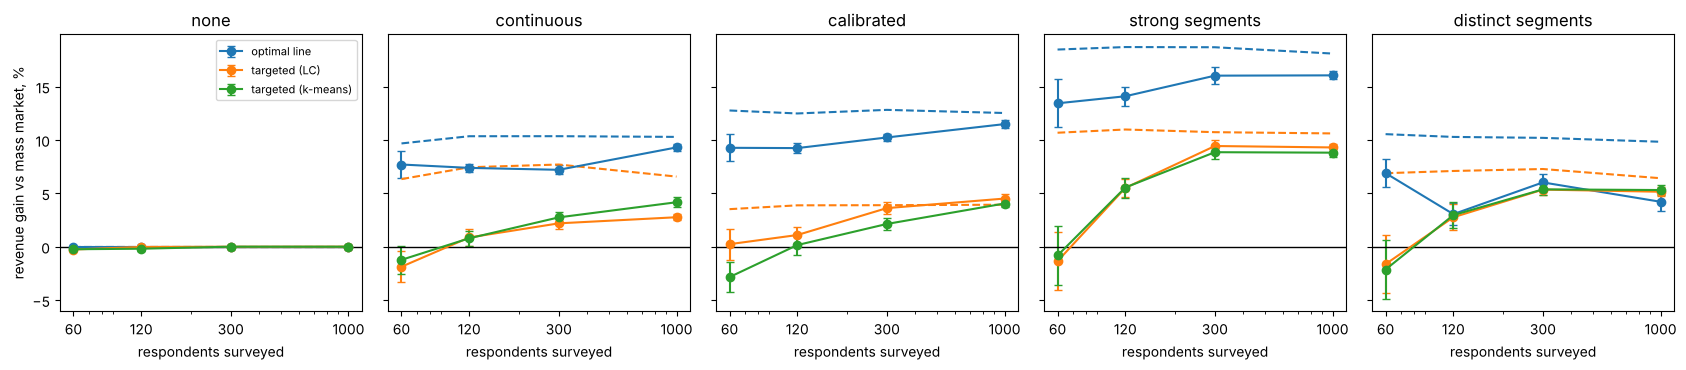

In [5]:
fig, ax = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True)
colors = {"optimal line": "C0", "targeted (LC)": "C1", "targeted (k-means)": "C2"}
for a, s in zip(ax, order):
    d = g[g["structure"] == s].drop(columns="structure").groupby("n")
    m, e = d.mean(), d.sem()
    for name in strategies:
        a.errorbar(m.index, m[name], yerr=e[name], marker="o", capsize=3, color=colors[name], label=name)
    a.plot(m.index, m["line potential"], "--", color="C0")
    a.plot(m.index, m["targeted potential"], "--", color="C1")
    a.axhline(0, color="k", lw=1)
    a.set_xscale("log")
    a.set_xticks([60, 120, 300, 1000])
    a.set_xticklabels([60, 120, 300, 1000])
    a.set_title(s)
    a.set_xlabel("respondents surveyed")
ax[0].set_ylabel("revenue gain vs mass market, %")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../figures/simulation.png", dpi=150, bbox_inches="tight")
plt.show()

Main results:
- **No heterogeneity:** no strategy gains anything (targeting loses up to 0.3%). So the pipeline does not create gains that are not there.
- **Targeting segments needs both distinct segments and a large survey.** With 60 respondents it loses money in every structure. In the calibrated market it gives about +1% at 120 respondents (the size of the real study) and only reaches +4% at 1000. With strong segments it gets close to its potential from about 300 respondents.
- **The optimal line is the safer strategy.** It gains in every heterogeneous market, already with 60 respondents, and realizes 70-90% of its potential in the continuous, calibrated and strong-segment markets.
- **Exception: distinct, tight segments.** Here the line realizes much less of its potential and is noisy across sample sizes, and from 300 respondents targeting is as good as the line (and better with 2 products, see below). HB assumes normally distributed preferences, so it blurs tight segments, and a line chosen on HB estimates suffers. LC assumes exactly this kind of structure.
- **Real data vs simulation at the calibrated point.** The ordering is the same as in part 4 (line clearly positive, targeting around zero), but the realized line gain is larger in the simulation (+9% vs +4% on the real data). The simulation evaluates on the true partworths of 1000 consumers, while the real-data evaluation uses estimated partworths of 61 respondents, and real preferences need not follow the assumed distribution.

## 2 vs 3 segments

In [6]:
k2 = pd.DataFrame({"structure": sim["structure"], "n": sim["n"]})
for K in [2, 3]:
    k2[f"line K={K}"] = 100 * (sim[f"line{K} realized"] / sim["mass realized"] - 1)
    k2[f"targeted LC K={K}"] = 100 * (sim[f"targeted LC{K} realized"] / sim["mass realized"] - 1)
k2.groupby(["structure", "n"]).mean().round(1).reindex(order, level=0)

line K=2  targeted LC K=2  line K=3  targeted LC K=3
structure         n                                                         
none              60         0.0             -0.1       0.0             -0.3
                  120        0.0             -0.0       0.0             -0.0
                  300        0.0              0.0       0.0             -0.0
                  1000       0.0              0.0       0.0              0.0
continuous        60         5.3             -1.4       7.7             -1.9
                  120        4.6              0.7       7.4              0.9
                  300        3.7              0.7       7.2              2.2
                  1000       4.9              1.0       9.3              2.8
calibrated        60         5.8             -1.6       9.3              0.2
                  120        5.5              0.4       9.2              1.1
                  300        6.3              1.8      10.2              3.6
                  1000       7.3              1.3      11.5              4.5
strong segments   60         8.6              1.3      13.4             -1.4
                  120        7.2              4.7      14.1              5.5
                  300        9.1              8.9      16.0              9.4
                  1000       9.4              9.6      16.0              9.3
distinct segments 60         5.5              4.0       6.9             -1.6
                  120        2.4              3.6       3.0              2.8
                  300        3.6              4.9       6.0              5.3
                  1000       1.9              4.9       4.2              5.1

With 2 products the same pattern holds. In the distinct-segments market targeting with 2 LC segments beats the 2-product line from 120 respondents on.

**Answer so far.** Segmenting first and targeting each segment increases revenue only when the market really consists of well separated segments and the firm surveys several hundred respondents. In a market like the one in the data, where heterogeneity is mostly continuous, designing a product line directly from individual preferences captures more revenue at every sample size.